# Ambulance Pooling vs Stovepipe

Overlapping mortality distributions.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]


Loaded 98304 runs


In [2]:
p1 = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
p2 = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
assert (p1["scenario"].values == p2["scenario"].values).all()

delta = p1["death_rate_T1_BCAS"].values - p2["death_rate_T1_BCAS"].values
print(f"amb: {len(p1)} runs, median mort = {p1['death_rate_T1_BCAS'].median():.3f}")
print(f"stove: {len(p2)} runs, median mort = {p2['death_rate_T1_BCAS'].median():.3f}")
print(f"Delta median: {np.median(delta):.4f}")
print(f"Delta > 0 (amb worse): {(delta > 0.01).sum()} / {len(delta)} ({(delta > 0.01).mean():.1%})")
print(f"Delta < 0 (amb better): {(delta < -0.01).sum()} / {len(delta)} ({(delta < -0.01).mean():.1%})")


amb: 24576 runs, median mort = 0.000
stove: 24576 runs, median mort = 0.600
Delta median: -0.5000
Delta > 0 (amb worse): 54 / 24576 (0.2%)
Delta < 0 (amb better): 22655 / 24576 (92.2%)


## Mortality Distributions


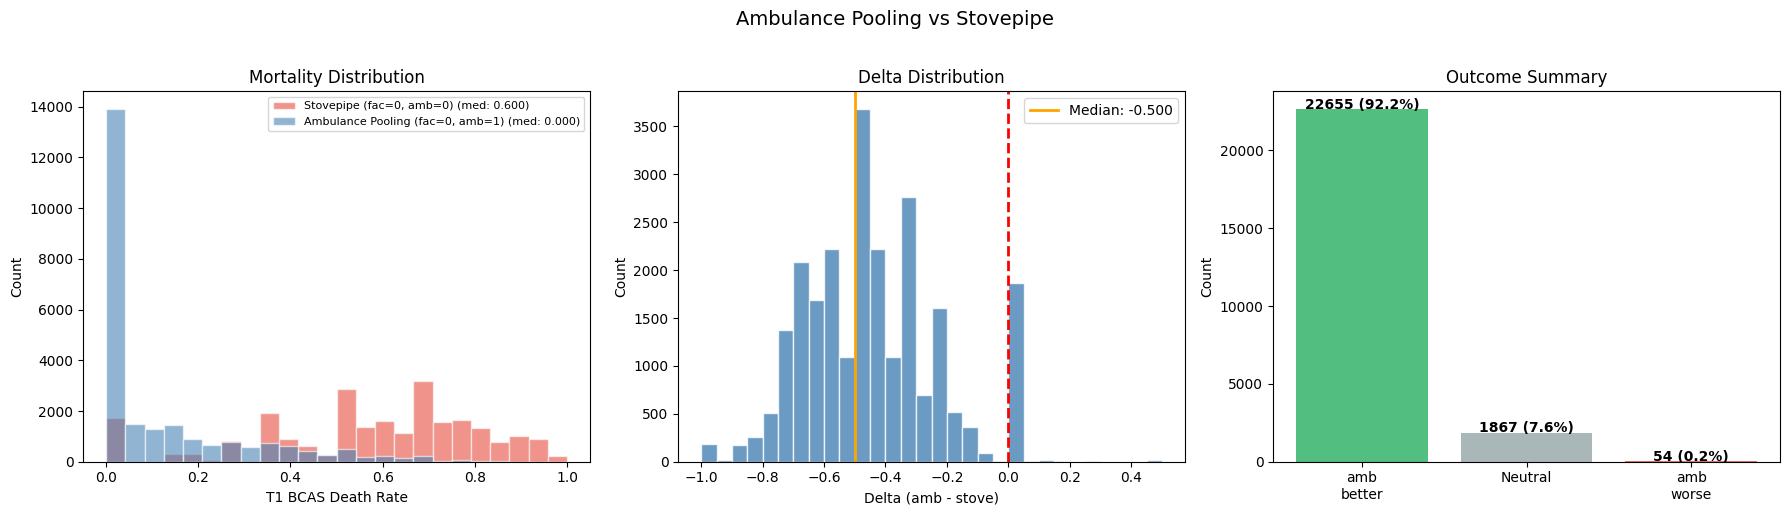

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bins = np.linspace(0, 1, 25)
axes[0].hist(p2["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Stovepipe (fac=0, amb=0) (med: {p2['death_rate_T1_BCAS'].median():.3f})")
axes[0].hist(p1["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Ambulance Pooling (fac=0, amb=1) (med: {p1['death_rate_T1_BCAS'].median():.3f})")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality Distribution")
axes[0].legend(fontsize=8)

axes[1].hist(delta, bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta), color="orange", linewidth=2, label=f"Median: {np.median(delta):.3f}")
axes[1].set_xlabel("Delta (amb - stove)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta Distribution")
axes[1].legend()

n_better = (delta < -0.01).sum()
n_neutral = ((delta >= -0.01) & (delta <= 0.01)).sum()
n_worse = (delta > 0.01).sum()
bars = axes[2].bar(["amb\nbetter", "Neutral", "amb\nworse"],
                    [n_better, n_neutral, n_worse],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_better, n_neutral, n_worse]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(delta):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome Summary")

fig.suptitle("Ambulance Pooling vs Stovepipe", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## Stressed scenarios only (bcas >= 0.02)


Stressed: 20478 scenarios


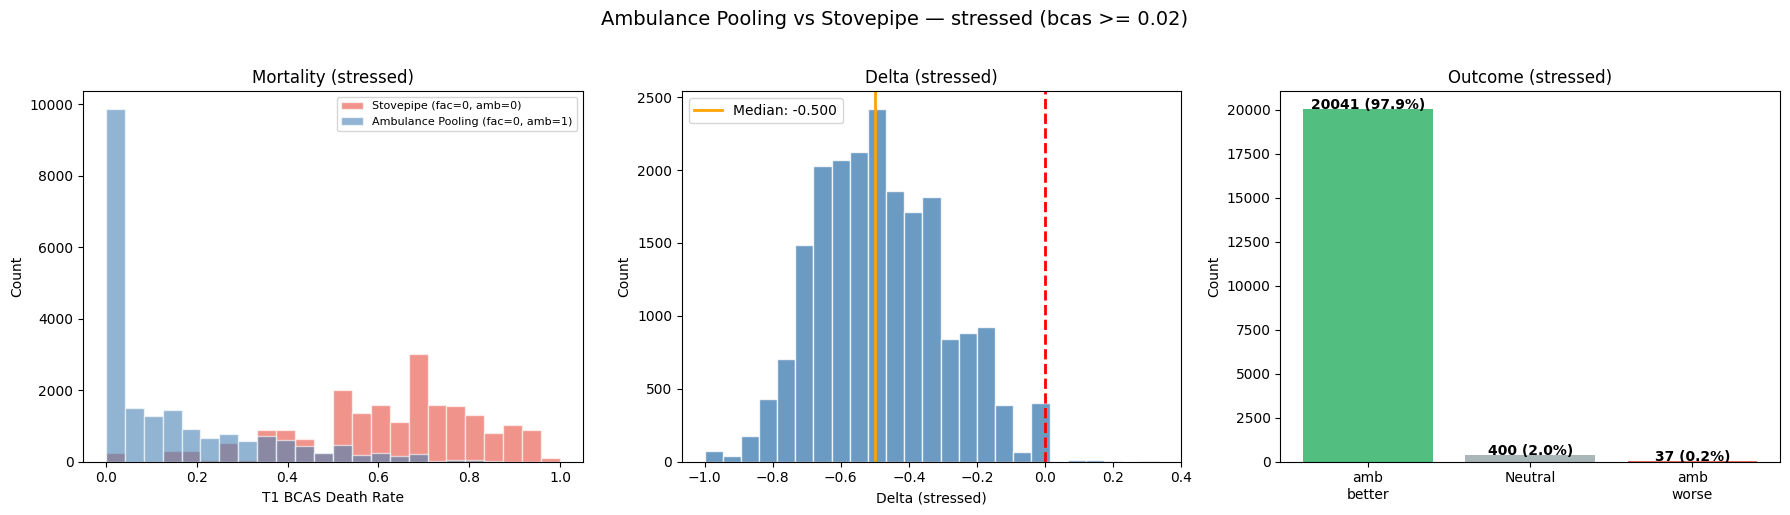

In [4]:
mask_s = p1["bcas_rate"] >= 0.02
p1s, p2s = p1[mask_s], p2[mask_s]
delta_s = p1s["death_rate_T1_BCAS"].values - p2s["death_rate_T1_BCAS"].values
print(f"Stressed: {len(p1s)} scenarios")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bins = np.linspace(0, 1, 25)
axes[0].hist(p2s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Stovepipe (fac=0, amb=0)")
axes[0].hist(p1s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Ambulance Pooling (fac=0, amb=1)")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality (stressed)")
axes[0].legend(fontsize=8)

axes[1].hist(delta_s, bins=25, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta_s), color="orange", linewidth=2, label=f"Median: {np.median(delta_s):.3f}")
axes[1].set_xlabel("Delta (stressed)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta (stressed)")
axes[1].legend()

n_b = (delta_s < -0.01).sum()
n_n = ((delta_s >= -0.01) & (delta_s <= 0.01)).sum()
n_w = (delta_s > 0.01).sum()
bars = axes[2].bar(["amb\nbetter", "Neutral", "amb\nworse"],
                    [n_b, n_n, n_w], color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_b, n_n, n_w]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f"{val} ({val/len(delta_s):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome (stressed)")

fig.suptitle("Ambulance Pooling vs Stovepipe — stressed (bcas >= 0.02)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## PRIM — Where does this policy help more than stovepipe?


Policy helped (delta < -0.01): 22655 / 24576 (92.2%)



Box where policy helps:
coverage       0.145928
density        0.997586
id            26.000000
k           3306.000000
mass           0.134847
mean           0.997586
n           3314.000000
res_dim        5.000000
Name: 26, dtype: float64

                        box 26                                   
                           min        max      qp value  qp value
waves_per_day         1.000000   5.500000           NaN  0.121385
bcas_rate             0.028143   0.069995  4.615324e-79       NaN
wave_duration_min    22.500000  60.000000  4.888142e-04       NaN
ccp_r1_same_bn_min   11.500000  17.500000  2.860645e-01  0.111615
ccp_r1_inter_bn_min  15.500000  29.500000  5.378988e-01  0.086116



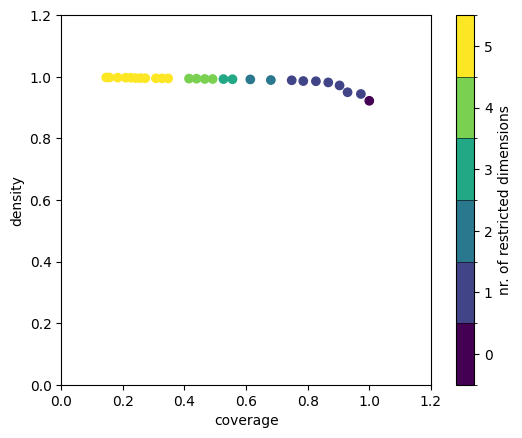

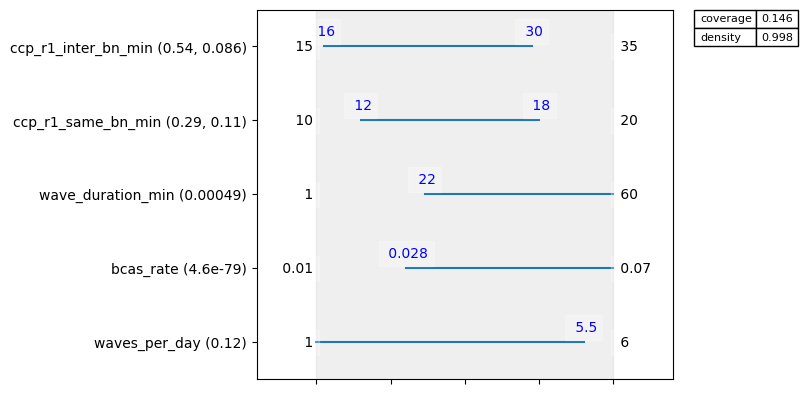

In [5]:
from ema_workbench.analysis import prim

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
x = p1[UNCERTAINTIES].astype(float)
y_better = (delta < -0.01)

print(f"Policy helped (delta < -0.01): {y_better.sum()} / {len(y_better)} ({y_better.mean():.1%})")

if y_better.sum() >= 10 and y_better.sum() < len(y_better) * 0.95:
    p = prim.Prim(x, y_better, threshold=0.5)
    box = p.find_box()
    box.show_tradeoff()
    print()
    print("Box where policy helps:")
    box.inspect(style="graph")
    box.inspect()
elif y_better.sum() >= len(y_better) * 0.95:
    print("Policy helps in >95% of cases — no meaningful box to find.")
else:
    print("Too few cases for PRIM.")


## PRIM — Where does this policy fail to help?


Policy did NOT help (delta >= -0.01): 1921 / 24576 (7.8%)



Box where policy fails to help:
coverage        1.000000
density         0.078166
id              0.000000
k            1921.000000
mass            1.000000
mean            0.078166
n           24576.000000
res_dim         0.000000
Name: 0, dtype: float64

Empty DataFrame
Columns: [(box 0, min), (box 0, max), (box 0, qp value), (box 0, qp value)]
Index: []



C:\Users\User\AppData\Local\Programs\Python\Python311\Lib\site-packages\ema_workbench\analysis\scenario_discovery_util.py:555: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(top=-0.5, bottom=nr_unc - 0.5)


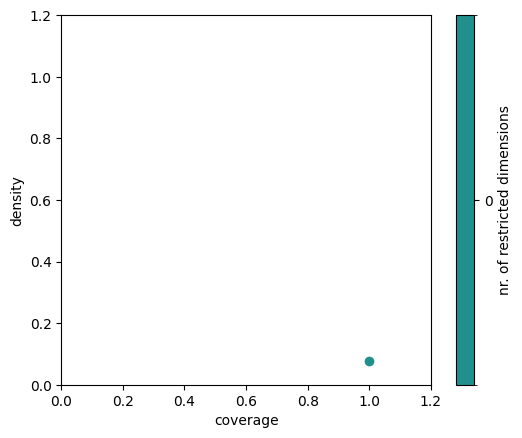

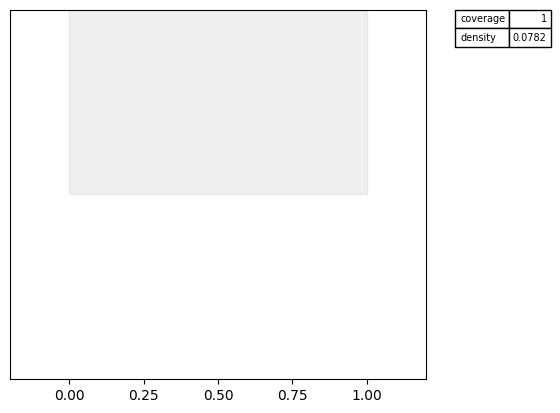

In [6]:
y_not_help = (delta > -0.01)

print(f"Policy did NOT help (delta >= -0.01): {y_not_help.sum()} / {len(y_not_help)} ({y_not_help.mean():.1%})")

if y_not_help.sum() >= 10 and y_not_help.sum() < len(y_not_help) * 0.95:
    p2 = prim.Prim(x, y_not_help, threshold=0.5)
    box2 = p2.find_box()
    box2.show_tradeoff()
    print()
    print("Box where policy fails to help:")
    box2.inspect(style="graph")
    box2.inspect()
elif y_not_help.sum() >= len(y_not_help) * 0.95:
    print("Policy fails to help in >95% of cases — no meaningful box to find.")
else:
    print("Too few cases for PRIM.")
